In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, r2_score

In [ ]:
from google.colab import drive
file_link = 'https://drive.google.com/file/d/1TcHOvdYd9ORopaNUq7fpu_FNXyh9_6dA/view?usp=sharing' # the file access must have to be Public
id = file_link.split("/")[-2]
new_link = f'https://drive.google.com/uc?id={id}'
data = pd.read_csv(new_link)

In [ ]:
# Shape of the data
data.shape

(195, 24)

In [ ]:
# Display basic information about the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 non-null    float64
 1

In [ ]:
# Rename columns to remove special characters
data.columns = data.columns.str.replace('[^A-Za-z0-9_]+', '', regex=True)

In [ ]:
# Describe the dataset
data.describe()

,MDVPFoHz,MDVPFhiHz,MDVPFloHz,MDVPJitter,MDVPJitterAbs,MDVPRAP,MDVPPPQ,JitterDDP,MDVPShimmer,MDVPShimmerdB,...,ShimmerDDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,...,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,...,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,...,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,...,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,...,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


In [ ]:
# Check for missing values in the dataset
data.isnull().sum().sum()

np.int64(0)

In [ ]:
# Check for duplicate rows in the dataset
data.duplicated().sum()

np.int64(0)

In [ ]:
# Value distribution of the target variable
data['status'].value_counts()

,count
status,
1,147
0,48


/tmp/ipython-input-4030780849.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status', data=df, palette="Set2")


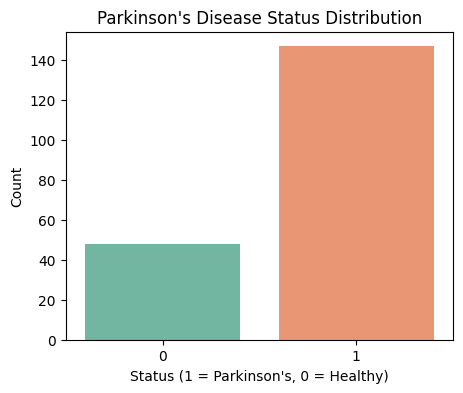

In [ ]:
# Parkinson's Disease Detection - Initial EDA
import seaborn as sns

# Load dataset
df = data

# Target Variable Distribution
plt.figure(figsize=(5,4))
sns.countplot(x='status', data=df, palette="Set2")

plt.title("Parkinson's Disease Status Distribution")
plt.xlabel("Status (1 = Parkinson's, 0 = Healthy)")
plt.ylabel("Count")
plt.show()


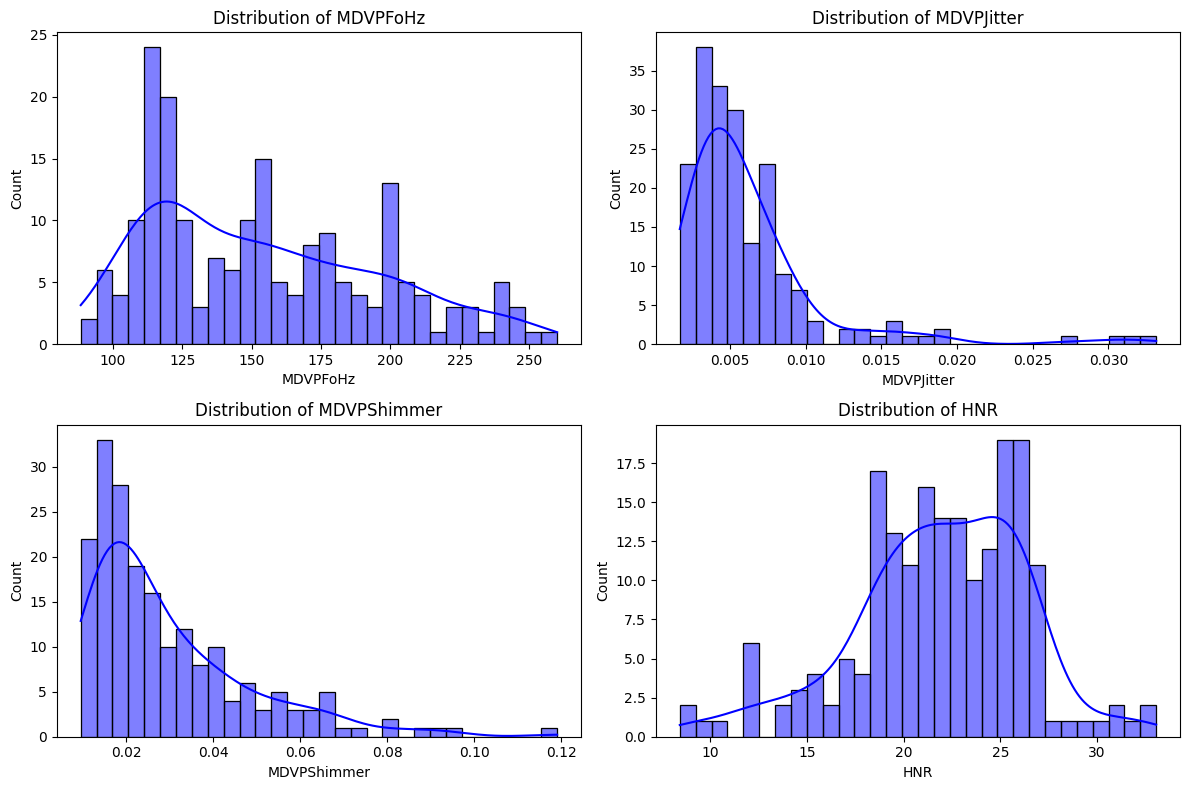

In [ ]:
#Distribution of Selected Features
features_to_plot = ['MDVPFoHz', 'MDVPJitter', 'MDVPShimmer', 'HNR']
plt.figure(figsize=(12,8))
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], kde=True, bins=30, color='blue')
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

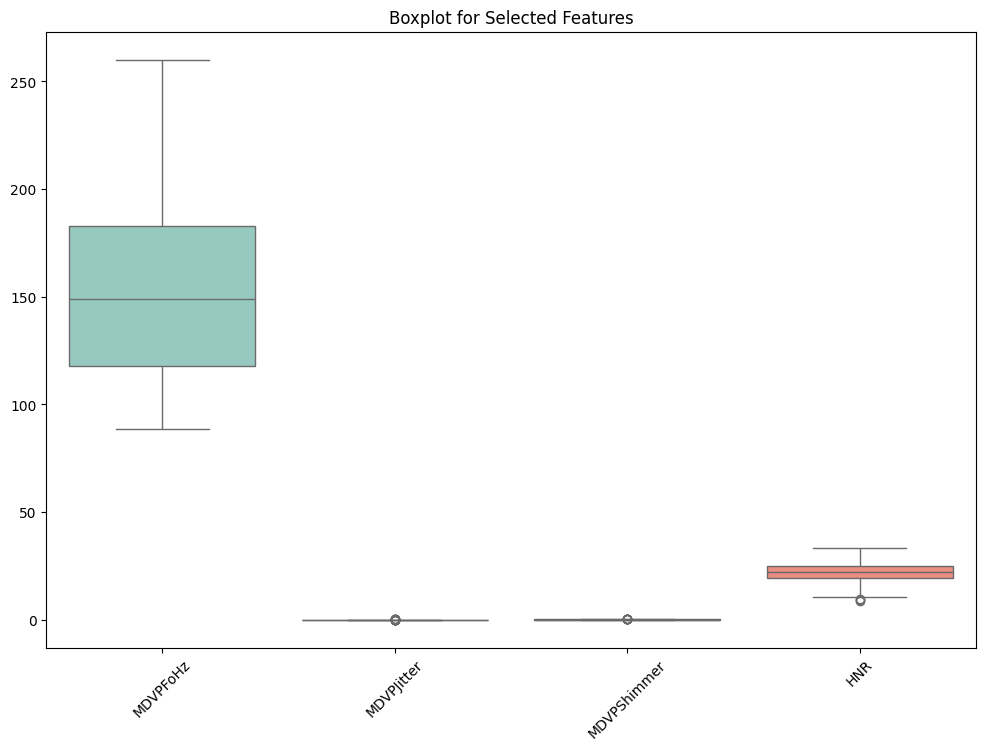

In [ ]:
#Boxplot to Check Outliers
plt.figure(figsize=(12,8))
sns.boxplot(data=df[features_to_plot], palette="Set3")
plt.title("Boxplot for Selected Features")
plt.xticks(rotation=45)
plt.show()

/tmp/ipython-input-1393533614.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='status', y=col, data=df, palette="coolwarm")
/tmp/ipython-input-1393533614.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='status', y=col, data=df, palette="coolwarm")
/tmp/ipython-input-1393533614.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='status', y=col, data=df, palette="coolwarm")
/tmp/ipython-input-1393533614.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` v

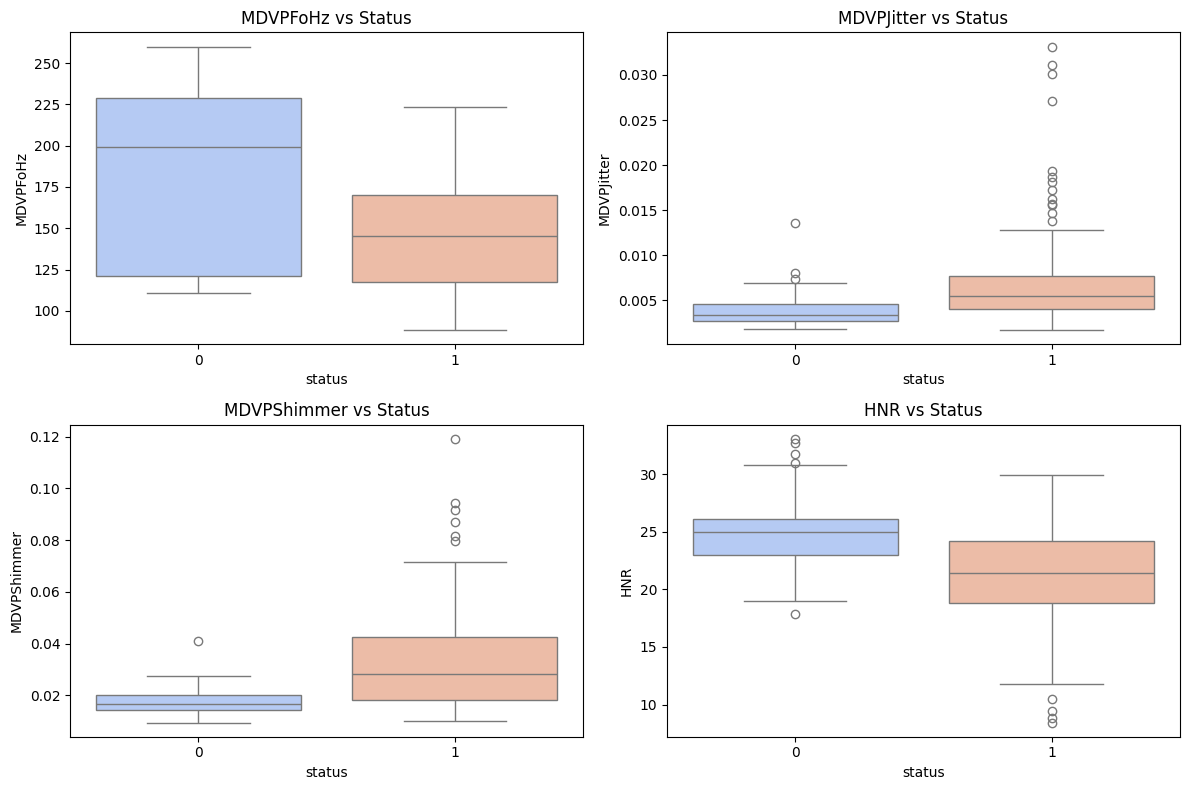

In [ ]:
#Feature Relationship with Target
plt.figure(figsize=(12,8))
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x='status', y=col, data=df, palette="coolwarm")
    plt.title(f"{col} vs Status")
plt.tight_layout()
plt.show()

In [ ]:
# Remove name column
data.drop('name', axis=1, inplace=True)

In [ ]:
# Separate features and target
X = data.drop(columns=['status'])  # Exclude target column
y = data['status']

In [ ]:
# Calculate correlation matrix
correlation_matrix = X.corr().abs()

# Select upper triangle of correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find features with correlation greater than 0.9
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]

# Drop highly correlated features
X = X.drop(columns=to_drop)
print(f"Dropped columns: {to_drop}")

Dropped columns: ['MDVPJitterAbs', 'MDVPRAP', 'MDVPPPQ', 'JitterDDP', 'MDVPShimmerdB', 'ShimmerAPQ3', 'ShimmerAPQ5', 'MDVPAPQ', 'ShimmerDDA', 'NHR', 'PPE']


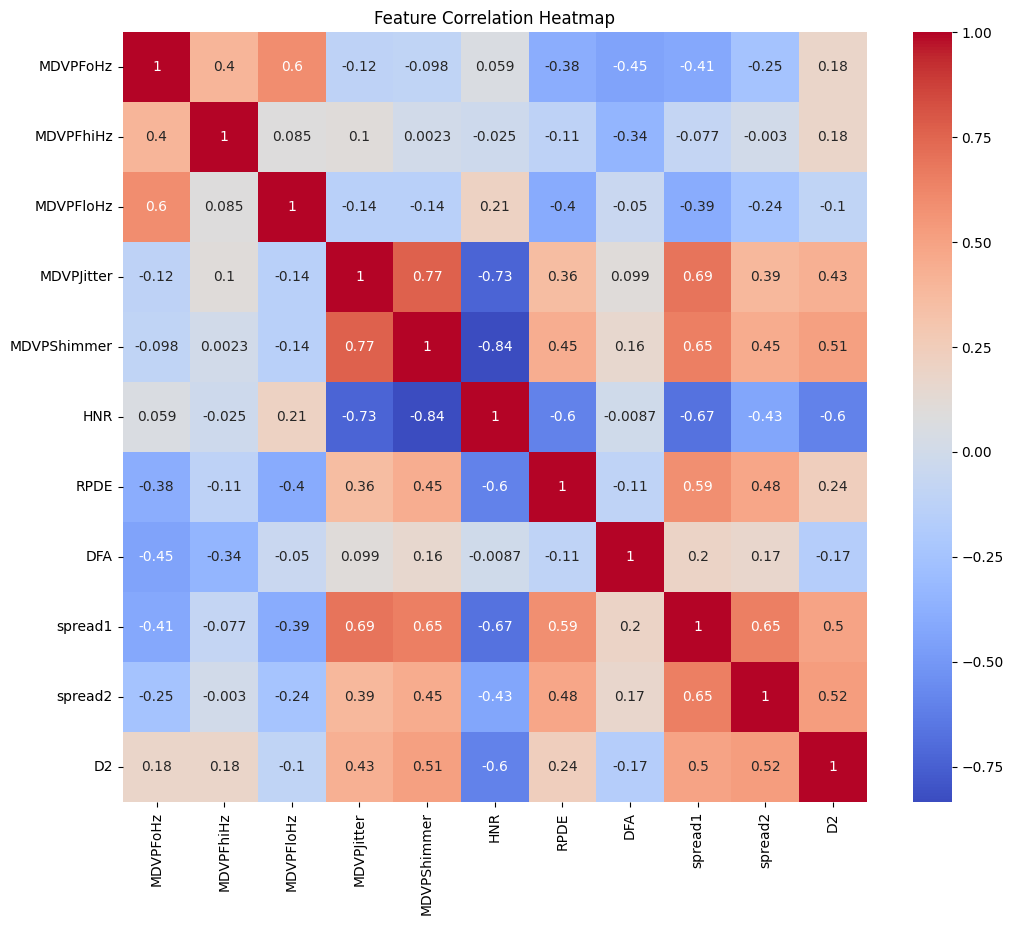

In [ ]:
# Visualize feature correlation
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap='coolwarm', annot=True)
plt.title('Feature Correlation Heatmap')
plt.show()

In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Scale the features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Model Training and Evaluation**

In [ ]:
def train_and_evaluate(models, X_train, X_test, y_train, y_test):
    metrics = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, zero_division=0)
        recall = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        r_squared = r2_score(y_test, y_pred)

        metrics.append({
            'Model': name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1,
            'R-Squared': r_squared
        })

        print(f"{name} - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, "
              f"Recall: {recall:.4f}, F1-Score: {f1:.4f}, R-Squared: {r_squared:.4f}")

    return pd.DataFrame(metrics)

# Updated models dictionary with Decision Tree, SVM, KNN
models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'AdaBoost_LogReg': AdaBoostClassifier(
        estimator=LogisticRegression(random_state=42, max_iter=1000),
        n_estimators=50,
        random_state=42
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        random_state=42
    ),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Train and evaluate models
metrics_df = train_and_evaluate(models, X_train, X_test, y_train, y_test)

LogisticRegression - Accuracy: 0.8974, Precision: 0.8889, Recall: 1.0000, F1-Score: 0.9412, R-Squared: 0.3036
AdaBoost_LogReg - Accuracy: 0.8974, Precision: 0.9118, Recall: 0.9688, F1-Score: 0.9394, R-Squared: 0.3036
RandomForest - Accuracy: 0.9231, Precision: 0.9394, Recall: 0.9688, F1-Score: 0.9538, R-Squared: 0.4777
DecisionTree - Accuracy: 0.8205, Precision: 0.9310, Recall: 0.8438, F1-Score: 0.8852, R-Squared: -0.2188
SVM - Accuracy: 0.9231, Precision: 0.9143, Recall: 1.0000, F1-Score: 0.9552, R-Squared: 0.4777
KNN - Accuracy: 0.9487, Precision: 0.9412, Recall: 1.0000, F1-Score: 0.9697, R-Squared: 0.6518


In [ ]:
metrics_df

,Model,Accuracy,Precision,Recall,F1-Score,R-Squared
0,LogisticRegression,0.897436,0.888889,1.00000,0.941176,0.303571
1,AdaBoost_LogReg,0.897436,0.911765,0.96875,0.939394,0.303571
2,RandomForest,0.923077,0.939394,0.96875,0.953846,0.477679
3,DecisionTree,0.820513,0.931034,0.84375,0.885246,-0.218750
4,SVM,0.923077,0.914286,1.00000,0.955224,0.477679
5,KNN,0.948718,0.941176,1.00000,0.969697,0.651786
